<a href="https://colab.research.google.com/github/darrenw002/-Adaptive-Embedded-AI-for-Anomaly-Detection-in-Edge-Devices/blob/main/Base_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Outlier detection

In [20]:
# 1) Get data
# random data generator (replace with import one we have data)
np.random.seed(42)
X_1d = np.random.rand(100, 1) * 10
y_1d = 30000 + X_1d.squeeze() + np.random.randn(100) * 5000
# display data
df = pd.DataFrame({'x values': X_1d.squeeze(), 'y values': y_1d})
print("Mock data head")
display(df.head())


Mock data head


,x values,y values
0,3.745401,30438.980742
1,9.507143,28514.470391
2,7.319939,30466.123822
3,5.986585,20068.142012
4,1.560186,28903.200747


In [21]:
# 2) Generate outliers
np.random.seed(42)
outlier_indices = [15, 35, 75]

# Adding outlier offsets
df.loc[outlier_indices[0], 'y values'] += 50000
df.loc[outlier_indices[1], 'y values'] -= 45000
df.loc[outlier_indices[2], 'y values'] += 60000

# Sync y_1d array with the modified dataframe
y_1d = df['y values'].values
print(f"Injected outliers at indices: {outlier_indices}")

Injected outliers at indices: [15, 35, 75]


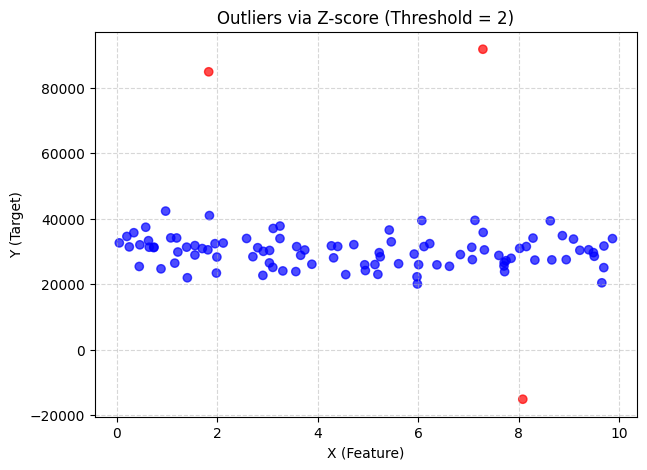

Z-score method found 3 outliers with threshold = 2.


,x values,y values,z_score,is_outlier_zscore
15,1.834045,84845.058998,5.203042,True
35,8.083973,-15124.485404,-4.394494,True
75,7.290072,91739.531119,5.864943,True


In [23]:
# Calculate Z-scores for 1D 'y' values
df['z_score'] = stats.zscore(df['y values'])

# Define Z-score threshold
threshold = 2
df['is_outlier_zscore'] = np.abs(df['z_score']) > threshold

# Plot
plt.figure(figsize=(7, 5))
plt.scatter(df['x values'], df['y values'], c=df['is_outlier_zscore'].map({True: 'red', False: 'blue'}), alpha=0.7)
plt.title(f'Outliers via Z-score (Threshold = {threshold})')
plt.xlabel('X (Feature)')
plt.ylabel('Y (Target)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Z-score method found {df['is_outlier_zscore'].sum()} outliers with threshold = {threshold}.")
display(df[df['is_outlier_zscore']])

# Drift detection

In [16]:
# 1. Generate motor temperature datasets (Baseline vs Current/Drifted)
np.random.seed(42)
baseline_motor_temp = np.random.normal(loc=70, scale=5, size=1000)       # Normal operations (mean=70°C)
current_motor_temp = np.random.normal(loc=75, scale=6, size=1000)        # after drift (mean=75°C)
# simulates motor running at normal temp for a period, then drifts up to a higher temp

# 2. Compute baseline stats
baseline_mean = np.mean(baseline_motor_temp)
baseline_std = np.std(baseline_motor_temp)

# 3. Define a simple threshold (e.g., alert if current mean shifts by more than 2 standard deviations)
sd_threshold = 1.0
allowed_drift_limit = sd_threshold * baseline_std

# 4. Compute current window stats
current_mean = np.mean(current_motor_temp)

# 5. Check for drift
mean_difference = abs(current_mean - baseline_mean)
is_drifted = mean_difference > allowed_drift_limit

print("=== Simple Mean-Shift Detector ===")
print(f"Baseline Mean Temperature: {baseline_mean:.2f}°C")
print(f"Current Mean Temperature:  {current_mean:.2f}°C")
print(f"Mean Shift Observed:       {mean_difference:.2f}°C")
print(f"Allowed Drift Limit:       {allowed_drift_limit:.2f}°C")
print(f"Numeric Drift Amount:      {mean_difference:.2f}°C")
print(f"Drift Detected?            {is_drifted}")

=== Simple Mean-Shift Detector ===
Baseline Mean Temperature: 70.10°C
Current Mean Temperature:  75.43°C
Mean Shift Observed:       5.33°C
Allowed Drift Limit:       4.89°C
Numeric Drift Amount:      5.33°C
Drift Detected?            True


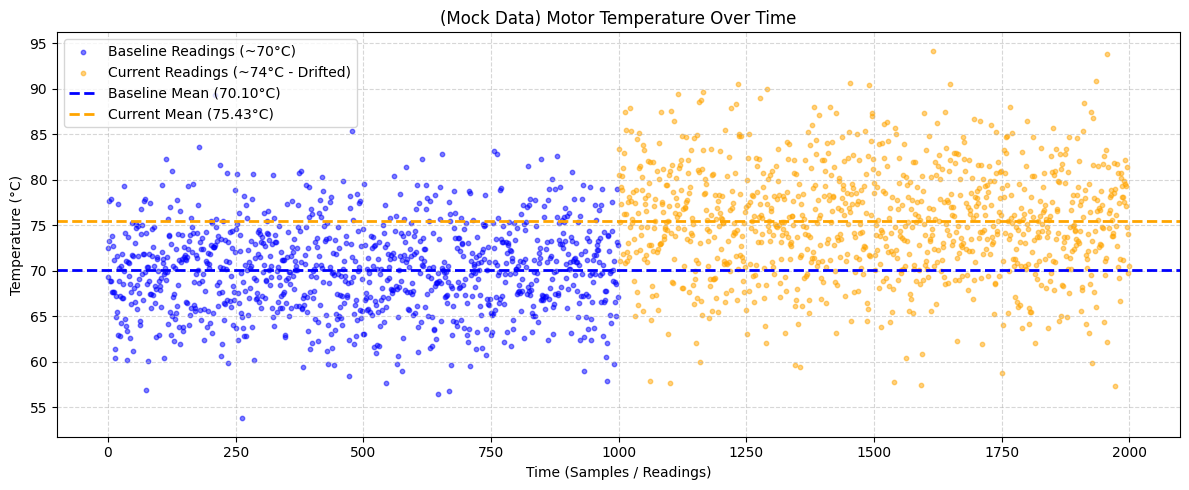

In [24]:
# Create a continuous time index representing a sequential timeline
# baseline first, followed immediately by current observations
time_baseline = np.arange(len(baseline_motor_temp))
time_current = np.arange(len(baseline_motor_temp), len(baseline_motor_temp) + len(current_motor_temp))

plt.figure(figsize=(12, 5))

# Plot base/curr phase as dots
plt.scatter(time_baseline, baseline_motor_temp, color='blue', alpha=0.5, s=10, label='Baseline Readings (~70°C)')
plt.scatter(time_current, current_motor_temp, color='orange', alpha=0.5, s=10, label='Current Readings (~74°C - Drifted)')

# Draw mean thresholds and lines
plt.axhline(baseline_mean, color='blue', linestyle='--', linewidth=2, label=f'Baseline Mean ({baseline_mean:.2f}°C)')
plt.axhline(current_mean, color='orange', linestyle='--', linewidth=2, label=f'Current Mean ({current_mean:.2f}°C)')

plt.title('(Mock Data) Motor Temperature Over Time')
plt.xlabel('Time (Samples / Readings)')
plt.ylabel('Temperature (°C)')
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()